# Precursor Characteristics per Search Engine

Compare peptide-level characteristics (length, charge state, missed cleavages, modifications)
across DIA search engines using the single best-settings result per tool.

Two views:
- **Global**: all unique precursors identified by each tool (union across all labs)
- **Excl. all-tools intersection**: precursors NOT shared simultaneously by every tool

In [2]:
import os
import pickle
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from SCI_py.constants.plotting import SOFTWARE_COLORS, LAB_ORDER
from SCI_py.plot.utilities import _save
from SCI_py.plot.overlap_search_engines import _SAMPLE_TYPE_A, _SAMPLE_TYPE_B

ZENODO_FOLDER = '/public/conode53/sam/SCI_paper/Zenodo'
DATA_PATH   = os.path.join(ZENODO_FOLDER, 'Data', 'ProteoBench')
FIGURE_PATH = '/home/sam/SCI/SCI/Figures/Figure_2/precursor_characteristics'

os.makedirs(FIGURE_PATH, exist_ok=True)

BEST_SETTINGS = {
    'AlphaDIA':                'Default',
    'MSAID':                   '5.0.0 MS2(Area) TIC-norm',
    'DIA-NN':                  'DIANN 2.6',
    'FragPipe (DIA-NN quant)': 'standard',
    'PEAKS':                   'MBR TIC-norm',
    'Spectronaut':             'DirectDIA+ method-evaluation',
}

ORDERING_TOOLS = ['Spectronaut', 'DIA-NN', 'PEAKS', 'FragPipe', 'AlphaDIA', 'MSAID']

In [3]:
with open(os.path.join(DATA_PATH, 'datapoints.pkl'), 'rb') as f:
    datapoints = pickle.load(f)
with open(os.path.join(DATA_PATH, 'intermediates.pkl'), 'rb') as f:
    intermediates = pickle.load(f)

def filter_best(df, best=BEST_SETTINGS):
    return df[df.apply(lambda r: r['comments'] == best.get(r['search_engine']), axis=1)].copy()

inter = filter_best(intermediates)
inter['search_engine'] = inter['search_engine'].replace({'FragPipe (DIA-NN quant)': 'FragPipe'})

print(f'{len(inter):,} rows | {inter["search_engine"].nunique()} tools | {inter["lab"].nunique()} labs')
print('Tools:', sorted(inter['search_engine'].unique()))

664,487 rows | 6 tools | 9 labs
Tools: ['AlphaDIA', 'DIA-NN', 'FragPipe', 'MSAID', 'PEAKS', 'Spectronaut']


In [4]:
# ── Lab groups ────────────────────────────────────────────────────────────────
# Each group produces a separate set of figures saved in FIGURE_PATH/<group_name>/.
# Add or modify groups here; the runner cell at the bottom iterates over all of them.
LAB_GROUPS = {
    'Astral':  sorted([l for l in inter['lab'].unique() if 'Astral'  in l]),
    'timsTOF': sorted([l for l in inter['lab'].unique() if 'timsTOF' in l]),
}
# Example custom group:  LAB_GROUPS['custom'] = ['Astral_1', 'Astral_3']

print('Lab groups:')
for name, labs in LAB_GROUPS.items():
    print(f'  {name}: {labs}')

Lab groups:
  Astral: ['Astral_1', 'Astral_2', 'Astral_3', 'Astral_4', 'Astral_5', 'Astral_6']
  timsTOF: ['timsTOF_1', 'timsTOF_2', 'timsTOF_3']


In [5]:
print('Columns:', inter.columns.tolist())
print()
print('Sample precursor ions per tool:')
for tool in [t for t in ORDERING_TOOLS if t in inter['search_engine'].unique()]:
    sample = inter[inter['search_engine'] == tool]['precursor ion'].dropna().iloc[:3].tolist()
    print(f'  {tool:30s} {sample}')

Columns: ['precursor ion', 'log_Intensity_mean_A', 'log_Intensity_mean_B', 'log_Intensity_std_A', 'log_Intensity_std_B', 'Intensity_mean_A', 'Intensity_mean_B', 'Intensity_std_A', 'Intensity_std_B', 'CV_A', 'CV_B', 'log2_A_vs_B', 'HYEA_QC_B13', 'HYEA_QC_B14', 'HYEA_QC_B15', 'HYEA_QC_B16', 'HYEA_QC_B17', 'HYEA_QC_B18', 'HYEA_QC_B19', 'HYEA_QC_B20', 'HYEA_QC_B21', 'HYEA_QC_B22', 'HYEA_QC_B23', 'HYEB_QC_O10', 'HYEB_QC_O11', 'HYEB_QC_O12', 'HYEB_QC_O2', 'HYEB_QC_O3', 'HYEB_QC_O4', 'HYEB_QC_O5', 'HYEB_QC_O6', 'HYEB_QC_O7', 'HYEB_QC_O9', 'nr_observed', 'YEAST', 'ECOLI', 'HUMAN', 'unique', 'species', 'log2_expectedRatio', 'epsilon', 'plate_id', 'lab', 'comments', 'search_engine', 'HYEB_QC_O8']

Sample precursor ions per tool:
  Spectronaut                    ['AAAAAAALQAK/2', 'AAAAAWEEPSSGNGTAR/2', 'AAADALSDLEIK/2']
  DIA-NN                         ['AAAAAAALQAK/2', 'AAAAADLANR/2', 'AAAAAWEEPSSGNGTAR/2']
  PEAKS                          ['AAAAAAALQAK/2', 'AAADALSDLEIK/2', 'AAADEWDER/2']
  Fra

In [6]:
_MOD_RE    = re.compile(r'\[.*?\]|\(.*?\)')
_ACETYL_RE = re.compile(r'(?i)acetyl|\+42')
_OX_RE     = re.compile(r'(?i)oxidation|\+16')

def _strip_mods(raw):
    s = _MOD_RE.sub('', raw).replace('_', '')
    return re.sub(r'[^A-Z]', '', s)

def _count_missed(seq):
    return sum(1 for i, aa in enumerate(seq[:-1]) if aa in 'KR' and seq[i + 1] != 'P')

def parse_precursor_chars(series):
    rows = []
    for prec in series:
        s     = str(prec)
        slash = s.rfind('/')
        if slash != -1:
            seq_raw    = s[:slash]
            cs         = s[slash + 1:].strip().lstrip('+')
            charge     = int(cs) if cs.isdigit() else np.nan
        else:
            seq_raw, charge = s, np.nan
        seq_clean = _strip_mods(seq_raw)
        rows.append({
            'charge':      charge,
            'pep_len':     len(seq_clean) if seq_clean else np.nan,
            'n_missed':    _count_missed(seq_clean) if seq_clean else np.nan,
            'is_modified': bool(_MOD_RE.search(seq_raw)),
            'has_acetyl':  bool(_ACETYL_RE.search(seq_raw)),
            'has_ox':      bool(_OX_RE.search(seq_raw)),
        })
    return pd.DataFrame(rows, index=series.index)


def _apply_min_prec(df, min_prec):
    """Require >= min_prec observations in each condition (A and B separately).

    Mirrors the ``per_condition=True`` logic in notebook 04's
    ``intermediate_to_upsetplotdf``. Falls back to ``nr_observed`` if
    the individual sample columns are absent.
    """
    a_cols = [c for c in df.columns if c in _SAMPLE_TYPE_A]
    b_cols = [c for c in df.columns if c in _SAMPLE_TYPE_B]
    if a_cols and b_cols:
        mask = (
            df[a_cols].notna().sum(axis=1) >= min_prec
        ) & (
            df[b_cols].notna().sum(axis=1) >= min_prec
        )
        return df[mask]
    if 'nr_observed' in df.columns:
        return df[df['nr_observed'] >= min_prec]
    return df


def _build_char_dfs(inter, labs=None, min_prec=3):
    """Build per-tool precursor characteristic tables for a lab subset.

    Parameters
    ----------
    inter : DataFrame
        Best-settings intermediates with FragPipe already renamed.
    labs : list of str, optional
        Restrict to these lab names. ``None`` uses all available labs.
    min_prec : int
        Minimum non-missing observations required in **each** condition
        (A and B) per lab row. Default 3, matching notebook 04.

    Returns
    -------
    char_global, char_excl, tools_present
    """
    inter_sub = inter[inter['lab'].isin(labs)] if labs is not None else inter
    if min_prec > 1:
        inter_sub = _apply_min_prec(inter_sub, min_prec)

    tp = [t for t in ORDERING_TOOLS if t in inter_sub['search_engine'].unique()]

    tool_prec_sets = inter_sub.groupby('search_engine')['precursor ion'].apply(set).to_dict()
    all_tools_set  = set.intersection(*(tool_prec_sets[t] for t in tp)) if len(tp) > 1 else (
        tool_prec_sets[tp[0]] if tp else set()
    )

    records = []
    for tool in tp:
        sub = (
            inter_sub[inter_sub['search_engine'] == tool]
            .drop_duplicates(subset='precursor ion')
            .reset_index(drop=True)
        )
        chars = parse_precursor_chars(sub['precursor ion'])
        chars['search_engine'] = tool
        chars['precursor ion'] = sub['precursor ion'].values
        chars['in_all_tools']  = sub['precursor ion'].isin(all_tools_set).values
        records.append(chars)

    if not records:
        empty = pd.DataFrame(columns=[
            'charge', 'pep_len', 'n_missed', 'is_modified',
            'has_acetyl', 'has_ox', 'search_engine', 'precursor ion', 'in_all_tools',
        ])
        return empty, empty, tp

    char_df     = pd.concat(records, ignore_index=True)
    char_global = char_df.copy()
    char_excl   = char_df[~char_df['in_all_tools']].copy()
    return char_global, char_excl, tp


MIN_PREC = 3  # minimum observations per condition (A and B); change here to adjust globally

# Default: all labs (for interactive exploration of individual figure cells below)
char_global, char_excl, tools_present = _build_char_dfs(inter, min_prec=MIN_PREC)

n_shared = char_global.loc[char_global['in_all_tools'], 'precursor ion'].nunique()
print(f'min_prec={MIN_PREC} per condition  |  All-tools intersection: {n_shared:,} unique precursors\n')
print(f'{"Tool":<30} {"Global":>8} {"Shared":>8} {"Excl.":>8}')
for t in tools_present:
    g = (char_global['search_engine'] == t).sum()
    s = int((char_global[char_global['search_engine'] == t]['in_all_tools']).sum())
    e = (char_excl['search_engine'] == t).sum()
    print(f'{t:<30} {g:8,d} {s:8,d} {e:8,d}')
print(f'\nModification annotations: {char_global["is_modified"].any()}  |  '
      f'Acetylation: {char_global["has_acetyl"].any()}  |  '
      f'Oxidation: {char_global["has_ox"].any()}')

min_prec=3 per condition  |  All-tools intersection: 11,136 unique precursors

Tool                             Global   Shared    Excl.
Spectronaut                      37,802   11,136   26,666
DIA-NN                           30,729   11,136   19,593
PEAKS                            22,357   11,136   11,221
FragPipe                         21,774   11,136   10,638
AlphaDIA                         27,107   11,136   15,971
MSAID                            16,122   11,136    4,986

Modification annotations: True  |  Acetylation: True  |  Oxidation: True


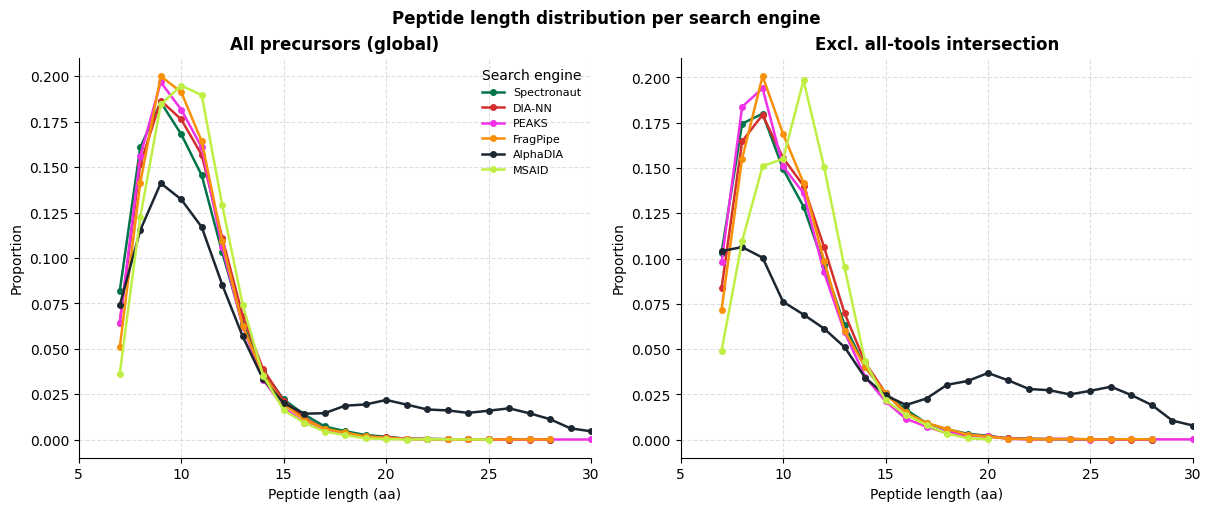

In [8]:
def _plot_pep_length(char_global, char_excl, tools_present,
                     save_dir=None, filename='pep_length', show=True):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    xlim = (5, 30)
    for ax, (df, title) in zip(axes, [
        (char_global, 'All precursors (global)'),
        (char_excl,   'Excl. all-tools intersection'),
    ]):
        for tool in tools_present:
            vals = df.loc[df['search_engine'] == tool, 'pep_len'].dropna()
            vals = vals[(vals >= xlim[0]) & (vals <= xlim[1])]
            if len(vals) < 10:
                continue
            counts = vals.value_counts(normalize=True).sort_index()
            ax.plot(counts.index, counts.values,
                    color=SOFTWARE_COLORS.get(tool, 'grey'), label=tool,
                    linewidth=1.8, marker='o', markersize=4)
        ax.set_xlabel('Peptide length (aa)')
        ax.set_ylabel('Proportion')
        ax.set_xlim(*xlim)
        ax.set_title(title, fontweight='bold')
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.set_axisbelow(True)
    axes[0].legend(title='Search engine', fontsize=8, frameon=False)
    fig.suptitle('Peptide length distribution per search engine', fontweight='bold')
    if save_dir:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            _save(fig, os.path.join(save_dir, filename))
    plt.show() if show else plt.close(fig)


_plot_pep_length(char_global, char_excl, tools_present)

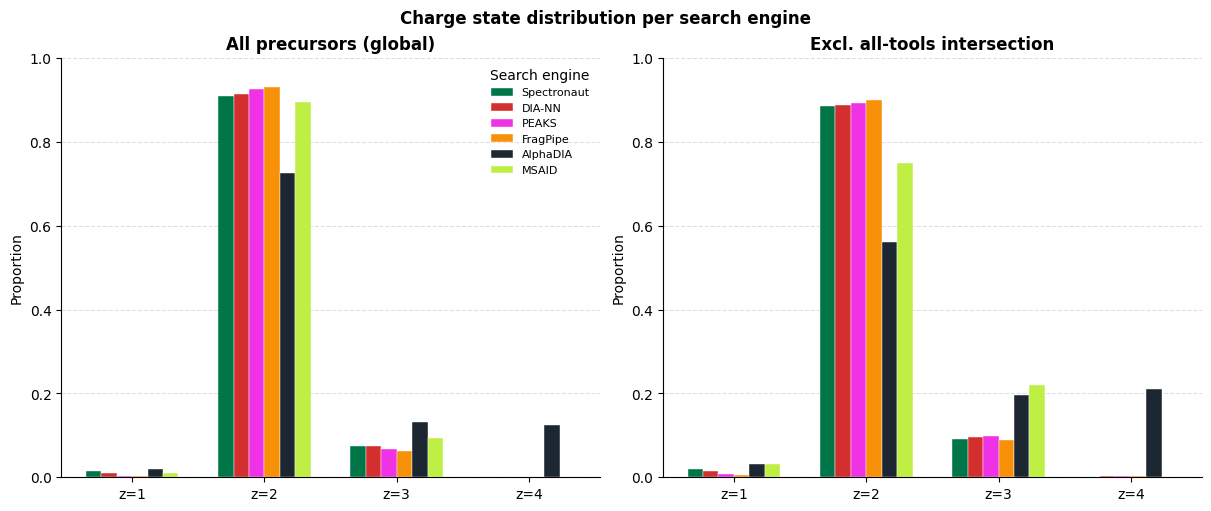

In [9]:
def _plot_charge(char_global, char_excl, tools_present,
                 save_dir=None, filename='charge_state', show=True):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    charge_vals = [1, 2, 3, 4]
    n_tools     = len(tools_present)
    bar_w       = 0.7 / n_tools
    for ax, (df, title) in zip(axes, [
        (char_global, 'All precursors (global)'),
        (char_excl,   'Excl. all-tools intersection'),
    ]):
        for j, tool in enumerate(tools_present):
            sub   = pd.to_numeric(df.loc[df['search_engine'] == tool, 'charge'], errors='coerce')
            sub   = sub.clip(upper=4).dropna()
            total = len(sub)
            props  = [(sub == c).sum() / total if total > 0 else 0 for c in charge_vals]
            offset = (j - n_tools / 2 + 0.5) * bar_w
            ax.bar(
                np.array(charge_vals) + offset, props,
                width=bar_w, color=SOFTWARE_COLORS.get(tool, 'grey'),
                label=tool, edgecolor='white', linewidth=0.3,
            )
        ax.set_xticks(charge_vals)
        ax.set_xticklabels([f'z={c}' for c in charge_vals])
        ax.set_ylabel('Proportion')
        ax.set_ylim(0, 1)
        ax.set_title(title, fontweight='bold')
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(True, axis='y', linestyle='--', alpha=0.4)
        ax.set_axisbelow(True)
    axes[0].legend(title='Search engine', fontsize=8, frameon=False)
    fig.suptitle('Charge state distribution per search engine', fontweight='bold')
    if save_dir:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            _save(fig, os.path.join(save_dir, filename))
    plt.show() if show else plt.close(fig)


_plot_charge(char_global, char_excl, tools_present)

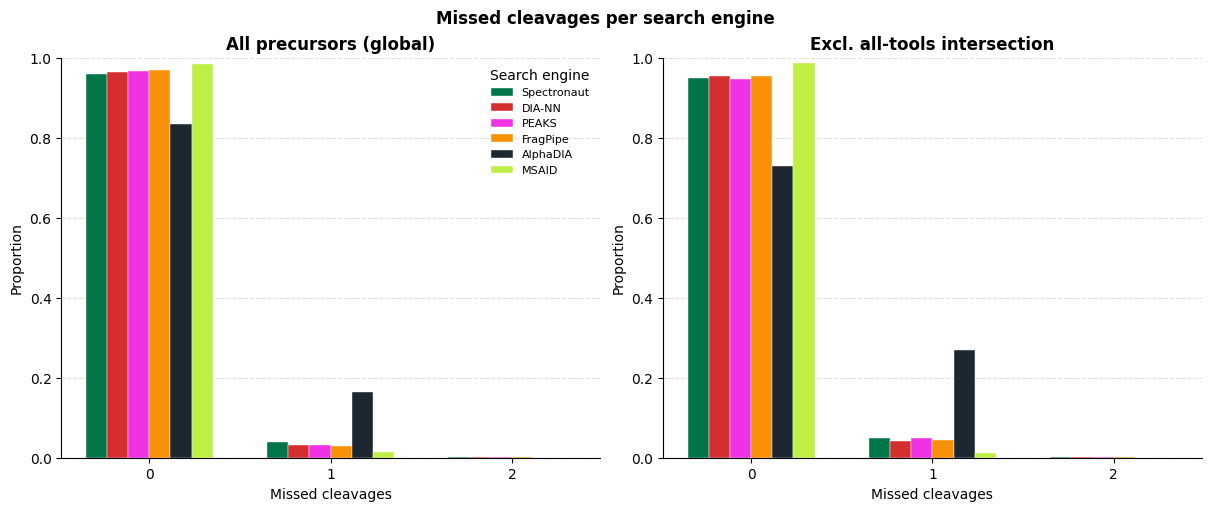

In [10]:
def _plot_missed(char_global, char_excl, tools_present,
                 save_dir=None, filename='missed_cleavages', show=True):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    mc_vals   = [0, 1, 2]
    mc_labels = ['0', '1', '2']
    n_tools   = len(tools_present)
    bar_w     = 0.7 / n_tools
    for ax, (df, title) in zip(axes, [
        (char_global, 'All precursors (global)'),
        (char_excl,   'Excl. all-tools intersection'),
    ]):
        for j, tool in enumerate(tools_present):
            sub   = pd.to_numeric(df.loc[df['search_engine'] == tool, 'n_missed'], errors='coerce')
            sub   = sub.clip(upper=3).dropna()
            total = len(sub)
            props  = [(sub == c).sum() / total if total > 0 else 0 for c in mc_vals]
            offset = (j - n_tools / 2 + 0.5) * bar_w
            ax.bar(
                np.arange(len(mc_vals)) + offset, props,
                width=bar_w, color=SOFTWARE_COLORS.get(tool, 'grey'),
                label=tool, edgecolor='white', linewidth=0.3,
            )
        ax.set_xticks(np.arange(len(mc_vals)))
        ax.set_xticklabels(mc_labels)
        ax.set_xlabel('Missed cleavages')
        ax.set_ylabel('Proportion')
        ax.set_ylim(0, 1)
        ax.set_title(title, fontweight='bold')
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(True, axis='y', linestyle='--', alpha=0.4)
        ax.set_axisbelow(True)
    axes[0].legend(title='Search engine', fontsize=8, frameon=False)
    fig.suptitle('Missed cleavages per search engine', fontweight='bold')
    if save_dir:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            _save(fig, os.path.join(save_dir, filename))
    plt.show() if show else plt.close(fig)


_plot_missed(char_global, char_excl, tools_present)

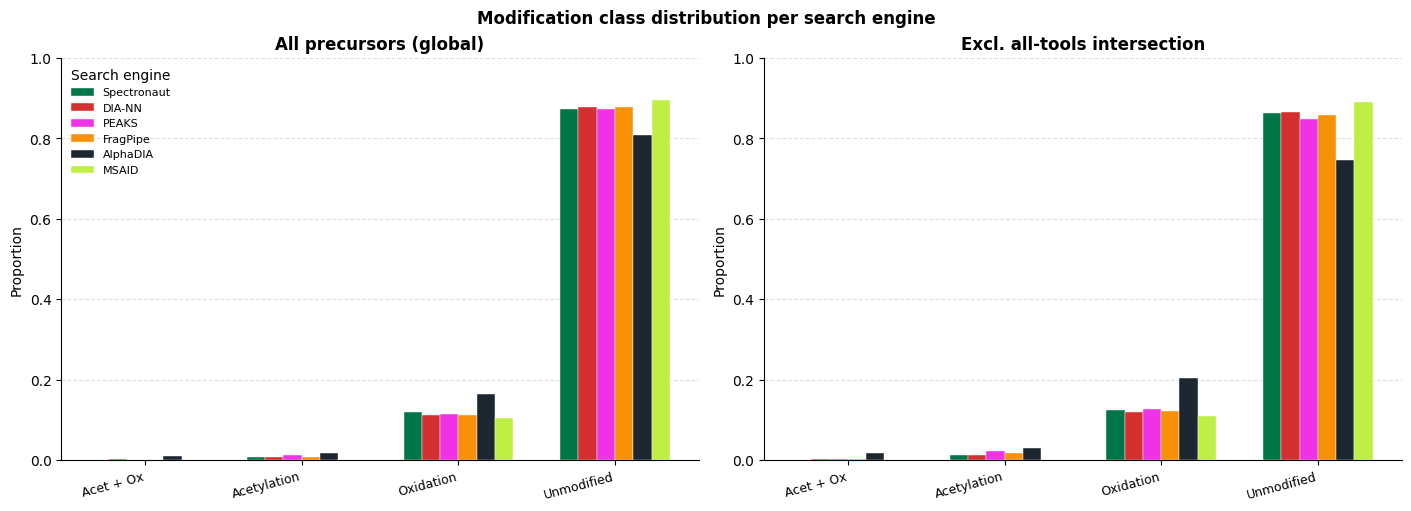

In [11]:
def _plot_mods(char_global, char_excl, tools_present,
               save_dir=None, filename='modifications', show=True):
    if not (char_global['has_acetyl'].any() or char_global['has_ox'].any()):
        print('No modification annotations — skipping modifications figure.')
        return

    mod_cats = ['Acet + Ox', 'Acetylation', 'Oxidation', 'Unmodified']
    n_tools  = len(tools_present)
    bar_w    = 0.7 / n_tools
    x_pos    = np.arange(len(mod_cats))

    def _mod_props(df, tool):
        sub   = df[df['search_engine'] == tool]
        total = len(sub)
        if total == 0:
            return [0.0, 0.0, 0.0, 0.0]
        ac, ox = sub['has_acetyl'], sub['has_ox']
        return [
            (ac & ox).sum()  / total,
            (ac & ~ox).sum() / total,
            (~ac & ox).sum() / total,
            (~ac & ~ox).sum() / total,
        ]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    for ax, (df, title) in zip(axes, [
        (char_global, 'All precursors (global)'),
        (char_excl,   'Excl. all-tools intersection'),
    ]):
        for j, tool in enumerate(tools_present):
            props  = _mod_props(df, tool)
            offset = (j - n_tools / 2 + 0.5) * bar_w
            ax.bar(
                x_pos + offset, props,
                width=bar_w, color=SOFTWARE_COLORS.get(tool, 'grey'),
                label=tool, edgecolor='white', linewidth=0.3,
            )
        ax.set_xticks(x_pos)
        ax.set_xticklabels(mod_cats, rotation=15, ha='right', fontsize=9)
        ax.set_ylabel('Proportion')
        ax.set_ylim(0, 1)
        ax.set_title(title, fontweight='bold')
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(True, axis='y', linestyle='--', alpha=0.4)
        ax.set_axisbelow(True)
    axes[0].legend(title='Search engine', fontsize=8, frameon=False)
    fig.suptitle('Modification class distribution per search engine', fontweight='bold')
    if save_dir:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            _save(fig, os.path.join(save_dir, filename))
    plt.show() if show else plt.close(fig)


_plot_mods(char_global, char_excl, tools_present)

In [12]:
# ── Run all figures for each lab group and save ───────────────────────────────
# Figures are saved to FIGURE_PATH/<group_name>/.
# Add entries to LAB_GROUPS (cell above) to include additional subsets.
for group_name, labs in LAB_GROUPS.items():
    print(f'\n── {group_name} ({labs}) ──')
    cg, ce, tp = _build_char_dfs(inter, labs, min_prec=MIN_PREC)
    gdir = os.path.join(FIGURE_PATH, group_name)
    os.makedirs(gdir, exist_ok=True)
    _plot_pep_length(cg, ce, tp, save_dir=gdir, show=False)
    _plot_charge(cg, ce, tp, save_dir=gdir, show=False)
    _plot_missed(cg, ce, tp, save_dir=gdir, show=False)
    _plot_mods(cg, ce, tp, save_dir=gdir, show=False)
    print(f'  Saved to {gdir}')


── Astral (['Astral_1', 'Astral_2', 'Astral_3', 'Astral_4', 'Astral_5', 'Astral_6']) ──
  Saved to /home/sam/SCI/SCI/Figures/Figure_2/precursor_characteristics/Astral

── timsTOF (['timsTOF_1', 'timsTOF_2', 'timsTOF_3']) ──
  Saved to /home/sam/SCI/SCI/Figures/Figure_2/precursor_characteristics/timsTOF
